# OIBSIP Task 4 – Email / SMS Spam Detection

Build an NLP binary classifier for spam vs ham. `data/sample_spam.csv` is synthetic demo data so the workflow can be tested immediately. For internship submission, use a real SMS Spam Collection dataset from UCI/Kaggle. The notebook prefers any CSV in `data/` other than the included sample.

**Quick start:** `python setup.py install` → `python setup.py check` → `python setup.py notebook`. Supports UCI `v1`/`v2` and `label`/`message` or `category`/`text` schemas.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import re, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
RANDOM_STATE=42
PROJECT_DIR=Path.cwd(); DATA_DIR=PROJECT_DIR/'data'; OUTPUT_DIR=PROJECT_DIR/'outputs'; OUTPUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
print('Project:',PROJECT_DIR)

Project: F:\gitproject\OIBSIP\OIBSIP_DataScience_Task4_EmailSpamDetection_Full\OIBSIP\DataScience-Task4-EmailSpamDetection


## 2. Load dataset

In [2]:
files=sorted(DATA_DIR.glob('*.csv'))
real=[p for p in files if p.name.lower()!='sample_spam.csv']
DATA_PATH=real[0] if real else DATA_DIR/'sample_spam.csv'
if not DATA_PATH.exists(): raise FileNotFoundError(f'No CSV found in {DATA_DIR}')
raw_df=pd.read_csv(DATA_PATH,encoding='utf-8',on_bad_lines='skip')
print('Using:',DATA_PATH.name,'Shape:',raw_df.shape)
display(raw_df.head())

Using: sample_spam.csv Shape: (240, 2)


,label,message
0,spam,Free entry in our contest text win to receive ...
1,ham,The meeting has been moved to Friday morning
2,spam,Winner notification collect your reward immedi...
3,ham,Please send me the notes from today class
4,spam,Free entry in our contest text win to receive ...


## 3. Normalize columns and labels
Classic UCI SMS Spam Collection uses `v1` (label) and `v2` (message).

In [3]:
def norm_col(x): return re.sub(r'[^a-z0-9]+','_',str(x).strip().lower()).strip('_')
df=raw_df.copy(); df.columns=[norm_col(c) for c in df.columns]
df=df.loc[:,~df.columns.str.startswith('unnamed')]
label_col=next((c for c in ['label','v1','category','class','type'] if c in df.columns),None)
text_col=next((c for c in ['message','v2','text','sms','email','body'] if c in df.columns),None)
if label_col is None or text_col is None: raise ValueError(f'Expected label/v1 and message/v2 columns. Found: {df.columns.tolist()}')
df=df[[label_col,text_col]].rename(columns={label_col:'label',text_col:'message'})
df['label']=df['label'].astype('string').str.strip().str.lower()
df['message']=df['message'].astype('string').fillna('').str.strip()
label_map={'spam':'spam','ham':'ham','1':'spam','0':'ham','junk':'spam','legitimate':'ham','not spam':'ham'}
df['label']=df['label'].map(label_map)
before=len(df); df=df.dropna(subset=['label']); df=df[df.message.str.len()>0].drop_duplicates(subset=['label','message']).reset_index(drop=True)
print('Removed invalid/empty/duplicate rows:',before-len(df),'Clean shape:',df.shape)
display(df.head())

Removed invalid/empty/duplicate rows: 178 Clean shape: (62, 2)


,label,message
0,spam,Free entry in our contest text win to receive ...
1,ham,The meeting has been moved to Friday morning
2,spam,Winner notification collect your reward immedi...
3,ham,Please send me the notes from today class
4,ham,Hi are we still meeting for lunch tomorrow


## 4. Class distribution

,count,percentage
label,,
ham,34,54.84
spam,28,45.16


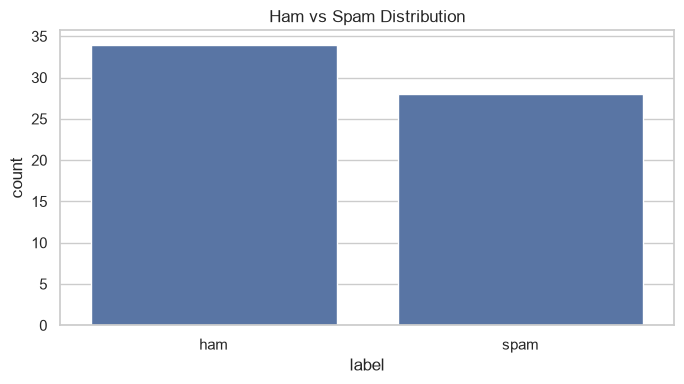

In [4]:
counts=df.label.value_counts().reindex(['ham','spam'],fill_value=0)
percent=(counts/counts.sum()*100).round(2)
display(pd.DataFrame({'count':counts,'percentage':percent}))
plt.figure(figsize=(7,4)); sns.countplot(data=df,x='label',order=['ham','spam']); plt.title('Ham vs Spam Distribution'); plt.tight_layout(); plt.savefig(OUTPUT_DIR/'class_distribution.png',dpi=150); plt.show()

## 5. Text preprocessing
Lowercase, remove URLs/email addresses, punctuation and digits, then remove a small stopword list. Negation words such as “not” and “no” are deliberately preserved because they can change meaning.

In [5]:
STOP_WORDS={'a','an','the','is','are','am','was','were','be','been','to','of','in','on','at','for','with','as','by','from','this','that','these','those','it','its','i','you','he','she','we','they','them','my','your','our','their','me','him','her','us','and','or','but','if','then','so'}
def preprocess_text(text):
    text=str(text).lower()
    text=re.sub(r'http\S+|www\.\S+',' ',text)
    text=re.sub(r'\S+@\S+',' ',text)
    text=re.sub(r'[^a-z\s]',' ',text)
    return ' '.join(w for w in text.split() if w not in STOP_WORDS)
df['clean_message']=df.message.apply(preprocess_text)
display(df[['message','clean_message','label']].head(10))

,message,clean_message,label
0,Free entry in our contest text win to receive ...,free entry contest text win receive bonus,spam
1,The meeting has been moved to Friday morning,meeting has moved friday morning,ham
2,Winner notification collect your reward immedi...,winner notification collect reward immediately,spam
3,Please send me the notes from today class,please send notes today class,ham
4,Hi are we still meeting for lunch tomorrow,hi still meeting lunch tomorrow,ham
5,Congratulations you have won a free prize clai...,congratulations have won free prize claim cash...,spam
6,Can you help me with the project this evening ...,can help project evening see soon,ham
7,You have been selected for a cash reward call now,have selected cash reward call now,spam
8,Can you help me with the project this evening,can help project evening,ham
9,Claim your free vacation prize by replying now,claim free vacation prize replying now,spam


## 6. TF-IDF feature extraction

**TF-IDF (Term Frequency–Inverse Document Frequency)** converts text into numbers. A term receives a higher weight when it appears often in one message but is relatively uncommon across the whole collection. Very common words receive lower weights. This helps the classifier focus on informative words.

We place `TfidfVectorizer` inside each pipeline so its vocabulary is learned only from training messages, avoiding test-set information leakage.

In [6]:
X=df['clean_message']; y=df['label']
if len(df)<10 or y.nunique()<2: raise ValueError('Need at least 10 valid messages and both ham and spam labels.')
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=RANDOM_STATE,stratify=y)
print('Train:',len(X_train),'Test:',len(X_test)); display(y_train.value_counts())

Train: 49 Test: 13


label
ham     27
spam    22
Name: count, dtype: int64

## 7. Train two classifiers: Multinomial Naive Bayes and Logistic Regression

In [7]:
models={
'Multinomial Naive Bayes':Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),max_features=20000)),('classifier',MultinomialNB())]),
'Logistic Regression':Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),max_features=20000)),('classifier',LogisticRegression(max_iter=1000,class_weight='balanced',random_state=RANDOM_STATE))])}
trained={}
for name,model in models.items(): model.fit(X_train,y_train); trained[name]=model; print(name,'trained')

Multinomial Naive Bayes trained
Logistic Regression trained


## 8. Evaluation: accuracy, precision, recall and F1-score

In [8]:
rows=[]
for name,model in trained.items():
    pred=model.predict(X_test)
    rows.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Precision':precision_score(y_test,pred,pos_label='spam',zero_division=0),'Recall':recall_score(y_test,pred,pos_label='spam',zero_division=0),'F1-score':f1_score(y_test,pred,pos_label='spam',zero_division=0)})
results_df=pd.DataFrame(rows).sort_values('F1-score',ascending=False).reset_index(drop=True)
display(results_df)

,Model,Accuracy,Precision,Recall,F1-score
0,Multinomial Naive Bayes,1.0,1.0,1.0,1.0
1,Logistic Regression,1.0,1.0,1.0,1.0


## 9. Confusion matrices and classification reports

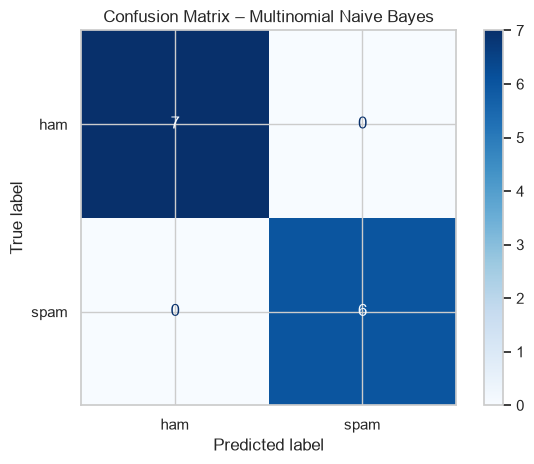

Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham       1.00      1.00      1.00         7
        spam       1.00      1.00      1.00         6

    accuracy                           1.00        13
   macro avg       1.00      1.00      1.00        13
weighted avg       1.00      1.00      1.00        13



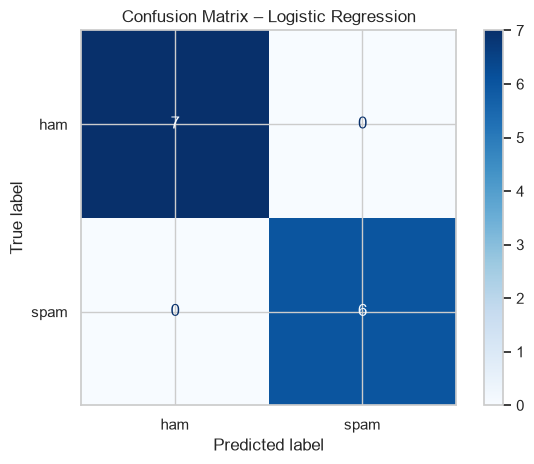

Logistic Regression
              precision    recall  f1-score   support

         ham       1.00      1.00      1.00         7
        spam       1.00      1.00      1.00         6

    accuracy                           1.00        13
   macro avg       1.00      1.00      1.00        13
weighted avg       1.00      1.00      1.00        13



In [9]:
for name,model in trained.items():
    pred=model.predict(X_test); cm=confusion_matrix(y_test,pred,labels=['ham','spam'])
    ConfusionMatrixDisplay(cm,display_labels=['ham','spam']).plot(cmap='Blues',values_format='d')
    plt.title('Confusion Matrix – '+name); plt.tight_layout()
    safe=re.sub(r'[^a-z0-9]+','_',name.lower()).strip('_'); plt.savefig(OUTPUT_DIR/f'confusion_matrix_{safe}.png',dpi=150); plt.show()
    print(name); print(classification_report(y_test,pred,labels=['ham','spam'],zero_division=0))

## 10. Why is recall particularly important for spam detection?

Spam recall measures the proportion of actual spam messages correctly identified. Low spam recall means many spam messages are misclassified as ham and reach the inbox. This can expose users to unwanted or deceptive messages.

Precision also matters: low precision means legitimate messages are incorrectly sent to spam. A useful filter balances both measures, because hiding an important legitimate message is also harmful.

## 11. Optional word-level visualisation

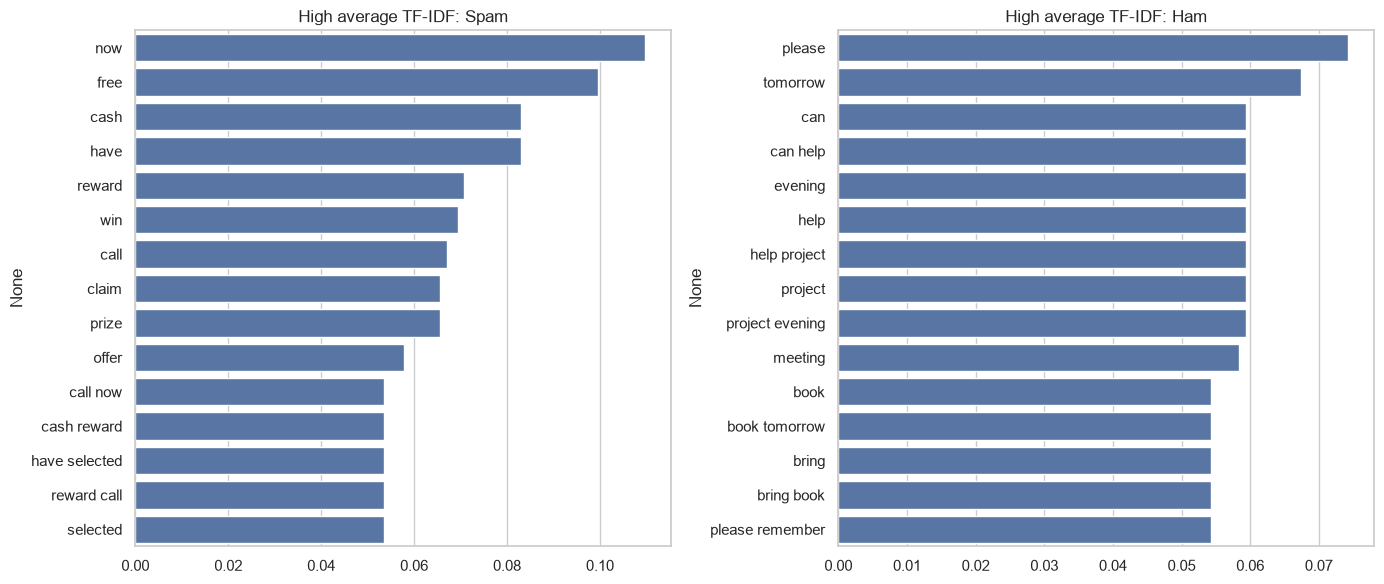

In [10]:
# Compare average TF-IDF terms by class as an interpretable descriptive view.
nb=trained['Multinomial Naive Bayes']; vec=nb.named_steps['tfidf']; mat=vec.transform(X_train); terms=np.array(vec.get_feature_names_out())
spam_mask=(y_train.to_numpy()=='spam'); ham_mask=(y_train.to_numpy()=='ham')
spam_avg=np.asarray(mat[spam_mask].mean(axis=0)).ravel(); ham_avg=np.asarray(mat[ham_mask].mean(axis=0)).ravel()
top_spam=pd.Series(spam_avg,index=terms).nlargest(15); top_ham=pd.Series(ham_avg,index=terms).nlargest(15)
fig,ax=plt.subplots(1,2,figsize=(14,6)); sns.barplot(x=top_spam.values,y=top_spam.index,ax=ax[0]); ax[0].set_title('High average TF-IDF: Spam'); sns.barplot(x=top_ham.values,y=top_ham.index,ax=ax[1]); ax[1].set_title('High average TF-IDF: Ham'); plt.tight_layout(); plt.savefig(OUTPUT_DIR/'top_terms_spam_ham.png',dpi=150); plt.show()

## 12. Bonus: WordCloud (optional; requires wordcloud package)

In [11]:
try:
    from wordcloud import WordCloud
    fig,ax=plt.subplots(1,2,figsize=(14,6))
    for a,label,title in [(ax[0],'spam','Spam WordCloud'),(ax[1],'ham','Ham WordCloud')]:
        text=' '.join(df.loc[df.label==label,'clean_message'])
        if text.strip(): a.imshow(WordCloud(width=800,height=450,background_color='white').generate(text),interpolation='bilinear')
        a.set_title(title); a.axis('off')
    plt.tight_layout(); plt.savefig(OUTPUT_DIR/'spam_ham_wordclouds.png',dpi=150); plt.show()
except ImportError:
    print('Optional package missing. Install with: python -m pip install wordcloud')

Optional package missing. Install with: python -m pip install wordcloud


## 13. Predict custom messages and save model

In [12]:
best_model_name=results_df.iloc[0]['Model']; best_model=trained[best_model_name]
print('Best model by F1-score:',best_model_name)
examples=['Congratulations! You won a free prize. Claim now.','Hi, are we still meeting at the library tomorrow?']
clean_examples=[preprocess_text(x) for x in examples]
for msg,pred in zip(examples,best_model.predict(clean_examples)): print('\nMessage:',msg,'\nPrediction:',pred.upper())
import joblib
joblib.dump(best_model,OUTPUT_DIR/'best_spam_classifier.joblib'); results_df.to_csv(OUTPUT_DIR/'model_metrics.csv',index=False)
print('Saved model and metrics to',OUTPUT_DIR.resolve())

Best model by F1-score: Multinomial Naive Bayes

Message: Congratulations! You won a free prize. Claim now. 
Prediction: SPAM

Message: Hi, are we still meeting at the library tomorrow? 
Prediction: HAM
Saved model and metrics to F:\gitproject\OIBSIP\OIBSIP_DataScience_Task4_EmailSpamDetection_Full\OIBSIP\DataScience-Task4-EmailSpamDetection\outputs


## 14. Conclusion (complete using the real dataset)

- Dataset name/source: record UCI or Kaggle source.
- Number of messages and ham/spam percentages: use the distribution table.
- Best model and accuracy, precision, recall, F1-score: copy from `results_df`.
- Discuss false positives and false negatives.
- Limitations: dataset style, language, changing spam tactics and generalisation to real email systems.

**Do not report synthetic demo scores as real-world results.**